# Optimization in Context

A reference for checking an optimization result, diagnosing a formulation, and communicating a decision recommendation. The examples separate model assumptions, numerical evidence, stakeholder preferences and implementation. The closing lecture uses these ideas to apply the earlier theory; the linked algorithm pages remain the primary homes of its proofs.

(ctx-quality)=
## Model quality, solve quality and decision quality

A numerical solve answers a question posed by a particular formulation. **Model quality** concerns whether the represented variables, physics, data, constraints and objective fit the intended task. **Solve quality** concerns the feasibility, stationarity, objective bounds and numerical accuracy achieved for that model. **Decision quality** also depends on whose preferences were represented, what uncertainty remains, what alternatives were excluded and whether the chosen action can be implemented. A strong result in one category does not establish the others.

The classical three-scenario [farmer model](../4/SP.ipynb) makes the distinction concrete. Its expected-value plan, evaluated with scenario recourse, earns expected profit 107,240; the recourse plan earns 108,390. The 1,150 difference is the value of the stochastic solution under that particular model (Birge and Louveaux, §4.2, p.165, using profits rather than the book's negative costs). These are model outcomes, not a measured probability of business failure. Every scenario profit is positive in this example. The expectation criterion, scenario probabilities and available crop decisions are still choices that deserve explanation. See the [information/risk examples](../4/Farmer_Zero_VSS.ipynb) for why uncertainty need not change a decision in every model.

Similarly, an accurately solved schedule that excludes a required changeover can be numerically excellent and operationally unusable. The correction begins in its representation, not in asking for another decimal place from the optimizer. Compare the intended process, model constraints, original residuals and planned implementation.

![Model, solve, choice and implementation have separate checks and feedback.](https://raw.githubusercontent.com/ndcbe/optimization/main/media/figures/ctx-quality-loop.png)

(ctx-model-algorithm)=
## A modeling feature suggests a diagnostic, not a verdict

The course's five-row map is useful when treated as a hypothesis generator:

| Feature | Candidate algorithmic difficulty | Evidence to inspect / primary home |
| --- | --- | --- |
| Disparate variable or residual scales | Conditioning and numerical accuracy | Units, scaled residuals and Jacobian singular values; [linear algebra](../6/Math-Primer.ipynb), [globalization](../6/Globalization.ipynb). |
| A kink or invalid derivative | Smooth-method hypotheses can fail | Formula, domain and derivative comparison; [Newton](../6/Newton-Methods.ipynb), [logical modeling](../2/Logical_Modeling_GDP.ipynb). |
| Dependent active gradients | Singular KKT system or ambiguous multipliers | Active-row rank and perturbation meaning; [constraint qualifications](../7/Constraint-Qualifications.ipynb) and [diagnostics](../7/degeneracy_hunter.ipynb). |
| Missing valid physical limits | Unsupported regions, domain errors or possible unboundedness | Original bounds/physics and objective behavior; [local feasibility](../7/Local-Optimality.ipynb), [barriers](../7/Barrier-Methods.ipynb). |
| Nonconvex structure | Local certificates may leave a global gap | Returned original feasibility and full objective bounds; [global optimization](Global-Opt.ipynb). |

A feature is not proof of a defect. Variables with different units can be represented well after an appropriate coordinate change. A nonconvex physical model can be scientifically necessary. LICQ failure can arise in an otherwise valid formulation. Conversely a solver's success flag does not validate the data or objective. Match observations to a testable explanation before changing equations.

![Five formulation features lead to candidate numerical checks.](https://raw.githubusercontent.com/ndcbe/optimization/main/media/figures/ctx-evidence-map.png)

(ctx-conditioning)=
## Read a conditioning report in its stated norm

For a nonsingular fixed matrix $\mathbf A$, the relative right-hand-side perturbation bound is

$$\frac{\|\Delta\mathbf x\|}{\|\mathbf x\|}\le\kappa(\mathbf A)\frac{\|\Delta\mathbf b\|}{\|\mathbf b\|},\qquad \kappa(\mathbf A)=\|\mathbf A\|\|\mathbf A^{-1}\|.$$

It follows from $\Delta\mathbf x=\mathbf A^{-1}\Delta\mathbf b$ and $\|\mathbf b\|\le\|\mathbf A\|\|\mathbf x\|$. This is the same induced norm on both sides, a bound for perturbing the RHS while holding the matrix fixed. If $\kappa=10^{10}$ and the relative RHS perturbation is $10^{-16}$, the bound is $10^{-6}$. It allows a loss of roughly ten digits in a worst-case direction; it does not say every solve actually loses exactly ten digits. Matrix perturbations require their own denominator/smallness conditions.

For a constraint Jacobian with reported condition $4.5\times10^{14}$, inspect scaling and near dependence separately. Dimensioned rows can span large magnitudes; nearly parallel rows can make the smallest singular value small even after units are corrected. Report the row/column scaling, norm, point and active-set convention used for the Jacobian. A small residual in one representation does not by itself guarantee an accurate physical solution.

In smooth unconstrained globalization, the bound $\cos\theta\ge1/\kappa(\mathbf B)$ for a positive-definite model matrix permits nearly orthogonal descent directions when conditioning is poor; it does not prove that every such iteration stalls. For logarithmic barriers, the fixed-parameter term $\mu\mathbf X^{-2}$ can create large curvature near a bound. Along an algorithm's changing central path both $\mu$ and $\mathbf X$ change, so inspect their ratio and the full KKT system. The [barrier guide](../7/Barrier-Methods.ipynb) gives the actual derivation.

![The perturbation expression supplies an upper bound, with smaller actual errors possible.](https://raw.githubusercontent.com/ndcbe/optimization/main/media/figures/ctx-conditioning-bound.png)

(ctx-scaling-interpretation)=
## Scaling changes coordinates; recover the original decision

The row/column example and complete executable calculation live in [Math-Primer: row and column scaling](../6/Math-Primer.ipynb#ctx-scaling). It compares the same matrix and RHS under four representations and checks each recovered solution in the original equations. Keep that notebook as the computational source.

If equality row $i$ is divided by $r_i\ne0$, divide its RHS too. If column $j$ is divided by $d_j>0$, solve for $z_j=d_jx_j$ and return $x_j=z_j/d_j$. Combined scales must be reversed in the correct order. For nonlinear residual scaling, preserve the zero set of equality rows and the direction of inequality rows, and transform bounds/objectives consistently with the variable change. Multipliers also transform: a numerical value attached to a scaled row is not automatically the sensitivity per unit of the original quantity.

The example's condition numbers improve little under row scaling and substantially under column scaling. That demonstrates a representation issue for this particular matrix. It does not establish that row scaling is generally ineffective, that the underlying measurements are correct, or that a near-dependent model can always be repaired by changing units. Compare characteristic physical units, recovered variables and original residuals before accepting the change.

![The original matrix and its equivalent representations have different condition numbers.](https://raw.githubusercontent.com/ndcbe/optimization/main/media/figures/ctx-scaling-actual.png)

(ctx-smoothness)=
## Check the expression before choosing a reformulation

Smooth Newton and quasi-Newton guarantees use their stated differentiability and curvature hypotheses. A maximum at a crossing, an absolute value at zero, discontinuous branching or piecewise-linear table interpolation can violate those hypotheses. An inactive maximum branch, identical smooth branches, or a sufficiently smooth interpolation need not. Test the expression on the relevant domain rather than classifying it solely by its syntax.

For minimization of an absolute value, the epigraph is exact without binaries:

$$\min_x|x|\quad\Longleftrightarrow\quad\min_{x,t}t\quad\text{s.t.}\quad t\ge x,\ t\ge-x.$$

At fixed $x$, both rows require $t\ge\max(x,-x)=|x|$, and setting $t=|x|$ is feasible. Minimizing $t$ therefore recovers the same value. In a larger problem this replacement is exact when the objective and other uses permit choosing the smallest epigraph variable. The equality $t=|x|$ in an arbitrary nonmonotone model is a different constraint and need not be represented by these two rows alone. Discrete logical alternatives can require disjunctive/binary formulations; see the [logical modeling home](../2/Logical_Modeling_GDP.ipynb).

A logarithm is also not automatically a nonconvex model: $-\log x$ has second derivative $1/x^2>0$ on $x>0$. Sign, composition, equality versus inequality direction and domain matter. A bilinear physical balance or a binary–continuous relation may be nonconvex in its given form; a valid equivalent reformulation or convex relaxation changes the computational representation, not the physics it must retain.

![Two affine rows describe the convex absolute-value epigraph.](https://raw.githubusercontent.com/ndcbe/optimization/main/media/figures/ctx-smooth-epigraph.png)

(ctx-degeneracy)=
## Separate active-row dependence from its physical cause

The [constraint-qualification guide](../7/Constraint-Qualifications.ipynb) states LICQ and its multiplier implications. In the standard equality KKT system, if $\mathbf J^\mathsf T\boldsymbol\nu=\mathbf0$ for some nonzero $\boldsymbol\nu$, then the block matrix has null vector $(\mathbf0,\boldsymbol\nu)$. This explains a singularity from dependent rows. Diagnose whether it arose from a duplicated balance, a redundant active bound, a poor local representation, or another cause. Irreducible degenerate sets can have different sizes; they are not necessarily two identical equations. A single row $x^2\le0$ has zero active gradient at $x=0$ and fails LICQ without two duplicated equations.

Consider $\min x^2$ with $x=1$ and $2x=2$. Stationarity at the feasible point gives $2+\lambda_1+2\lambda_2=0$. The individual multipliers are not unique. However, the consistent perturbation $x=1+\epsilon$, $2x=2(1+\epsilon)$ has value $V(\epsilon)=(1+\epsilon)^2$ and derivative $V'(0)=2$. Thus a nonunique multiplier does not erase every meaningful sensitivity statement. A perturbation that changes only one duplicate row can instead make the equations inconsistent. State which physical quantity is being perturbed before interpreting a shadow price.

Dowling and Biegler(2015), p.811, motivates finding minimal degenerate equation sets rather than blindly deleting equations. The [diagnostics notebook](../7/degeneracy_hunter.ipynb) is the primary computational home. Structural and numerical findings deserve physical interpretation before a constraint is removed.

![Two equality residuals vanish at the same point and have dependent gradients.](https://raw.githubusercontent.com/ndcbe/optimization/main/media/figures/ctx-dependent-rows.png)

(ctx-bounds)=
## Bounds, domains and unbounded objectives are different

Missing a valid physical limit can let a model explore unsupported or numerically dangerous regions. It does not logically imply objective unboundedness: $\min_{x\in\mathbb R}x^2$ has attained minimum 0, while $\min_{x\in\mathbb R}(-x)$ is unbounded below. A logarithm additionally needs its argument positive for evaluation. A convenient artificial bound should not quietly substitute for the actual physical limit; record its origin and test whether it changes the result.

A finite LP optimum need not occur at a vertex when its feasible polyhedron has lineality. For $\min0$ on the real line, every point is optimal and none is an extreme point. A standard vertex statement needs the corresponding nonempty/attainment/pointedness or basic-feasible-solution assumptions. Infeasibility is a separate outcome. A variable becoming large in a local iterate is a symptom, not by itself a proof of unboundedness.

Interior-point models do not require a lower bound on every original variable. Inequality slacks can supply logarithmic barriers while some original variables remain free. For a bound $x>\ell$, the corresponding term $-\mu\log(x-\ell)$ has derivative $-\mu/(x-\ell)$ and second derivative $\mu/(x-\ell)^2$. Setting $\ell=-10^{20}$ makes its influence tiny at ordinary $x$ for ordinary $\mu$, but only for that term/parameter/scale. It does not establish that the entire solver is inactive. Valid finite boxes are also computational information for the [global relaxations](Global-Opt.ipynb), whose bounds must hold throughout the box.

![An unbounded variable domain can have an attained objective minimum or an unbounded objective.](https://raw.githubusercontent.com/ndcbe/optimization/main/media/figures/ctx-bounds-domains.png)

(ctx-diagnostic-workflow)=
## Use solver evidence to choose the next test

A termination message records algorithm behavior. Restoration failure does not certify that the original problem is infeasible. An evaluation error, inaccurate derivative, bad scaling, difficult initialization, dependent gradients, numerical limits or inconsistent constraints can require different responses. Preserve the model/data/version and the original log; make a checkpoint before changing it.

A defensible workflow is to inspect variable domains and units; check structural degrees of freedom and incidence; initialize a simpler or fixed-decision model; evaluate original residuals and derivatives; inspect scaling, numerical rank and active-set evidence; then choose an appropriate reformulation, initial point or solver option and rerun the relevant checks. This is an example order, not an instruction to ignore an option clearly implicated by the log. Do not repeatedly vary many controls at once, because the cause of improvement becomes unclear.

Lee et al.(2024), pp.968–969, reports thirteen interviews: users cited solver logs, model statistics, Jacobian inspection, incidence analysis and other tools; no interviewee knew all available tools. The paper distinguishes structural, numerical and advanced diagnostics, and proposes incremental model development with checkpoints and a square simulation test before releasing decision degrees of freedom. Its workflow is engineering guidance, not a theorem that every arbitrary optimization model must derive from a square process simulation. See [constrained globalization](../7/Constrained-Globalization.ipynb) for restoration's mathematical role and [diagnostics](../7/degeneracy_hunter.ipynb) for the course implementation.

![A diagnostic workflow preserves evidence and checkpoints between model changes.](https://raw.githubusercontent.com/ndcbe/optimization/main/media/figures/ctx-diagnostics-flow.png)

(ctx-certificates)=
## Say precisely what the numerical certificate covers

The [optimality](../6/Optimality.ipynb), [KKT](../7/KKT-Multipliers.ipynb) and [global](Global-Opt.ipynb) guides state the actual hypotheses. Small first-order residual alone is not a local-optimality proof: $f(x)=-x^2$ on $[-1,1]$ has zero derivative at 0, which is an interior maximum, while both endpoints have value−1. A second-order or convexity result supplies additional information only under its stated assumptions. Check original feasibility separately from solver termination.

For minimization, a checked original-feasible point gives $U$, and a valid whole-domain lower value gives $L\le f^*\le U$. A gap $U-L=.2$ certifies objective accuracy .2, not the distance to every minimizer and not exact optimum. With $L=9.8$, $U=10$, target .1 is unmet; target .2 is met in the mathematical certificate. Numerical tolerances and rounding need their own interpretation. A regional lower value that omits another region is not a global lower value. The [global-search guide](Global-Opt.ipynb#go-cover-certificate) retains the complete-cover argument rather than duplicating it here.

Record the solver/model scope of the claim: local stationarity, local sufficient conditions, a global objective interval or a limit status. A time limit can return a valuable feasible point and a nonzero lower bound without establishing the requested tolerance. A solver success message is not a validation of objective choice, empirical data or implementation.

![A global objective interval and a local residual describe different evidence.](https://raw.githubusercontent.com/ndcbe/optimization/main/media/figures/ctx-certificate-scope.png)

(ctx-uncertainty)=
## Choose a response to the uncertainty that matters

The six response verbs give a menu, not a universal strength ranking. They can be combined:

- **Ignore** a source in a deterministic approximation, with the omission declared and tested when material.
- **Explore** sensitivity to specified data or perturbations, using the assumptions of the [sensitivity result](../7/KKT-Multipliers.ipynb).
- **Learn** unknown parameters from observations; the [estimation material](../5/Parmest-tutorial.ipynb) gives a data/model example.
- **Reduce** uncertainty relevant to a decision by selecting informative experiments; see [experimental design](../5/Pyomo_DoE_Tutorial.ipynb).
- **Model** scenarios and recourse with the decision timing and probabilities explicit; see [stochastic programming](../4/SP.ipynb).
- **Protect** feasibility against every realization in a specified uncertainty set, the named robust-optimization direction.

The estimation/local-uncertainty and nonlinear-uncertainty/design teaching units are distinct; their methods remain complementary. More data does not automatically resolve disagreement over objectives. A larger uncertainty set can give conservative protection only relative to that set, not a guarantee for unrepresented events. Robust optimization is named here, not developed as another algorithm unit. Postek, Zocca, Gromicho and Kantor's *Hands-On Mathematical Optimization with Python*(2025), chapter 8, [robust production planning](https://mobook.github.io/MO-book/notebooks/08/01-robust-production-planning.html), is a starting point. Its companion notebooks are free online; the book itself is a separate publication.

![Six complementary uncertainty responses, with robust optimization named beyond the taught methods.](https://raw.githubusercontent.com/ndcbe/optimization/main/media/figures/uncertainty-responses.png)

(ctx-boundary)=
## Document the boundary drawn around the model

Rittel and Webber(1973), p.160, distinguishes problems with an agreed mission/completion criterion from planning problems whose formulation and evaluation remain contested. Their optimization example on p.162 identifies choosing the alternative space, constraints and performance measure as part of the difficult formulation. This is a qualitative planning argument; it does not make every numerical model uniquely solved or every model failure a wicked problem.

For the classical farmer example, acreage among three crops is the available first-stage choice; three equally likely yields stand in for a broader possible distribution; the scalar criterion is expected profit with recourse. Insurance, a fourth crop, land sale or a stakeholder's debt-risk requirement cannot be recommended unless represented or assessed separately. These boundary choices need not be errors. They are assumptions to communicate, challenge and revisit when the intended decision requires it.

Driscoll, Parnell and Henderson(2023), Table 1.1, p.9, describes a technical/complex/wicked spectrum across ten dimensions. Its examples of clear testable outcomes are a systems-engineering classification, not a theorem that a well-posed optimization problem has exactly one optimal point. Mathematical nonuniqueness and organizational ambiguity are different.

Two of the source table's ten dimensions illustrate its qualitative spectrum:

| Dimension | Technical | Complex | Wicked |
| --- | --- | --- | --- |
| Evaluating a solution | Clear testable criterion | Defensible outcomes assessed with objective and subjective evidence | No agreed objectively testable best solution |
| Ending the effort | Stated completion/optimality target | Implementing a good outcome can expose new needs | No intrinsic clear stopping point |

These are planning descriptions, not assumptions that rule out multiple mathematical optima. Their chapter 2, p.52, describes well-structured improvement within an accepted system representation. A project can contain a solvable technical subproblem while its wider goals remain contested.

On p.162 Rittel/Webber discusses stopping a planning effort for external reasons such as limited resources. A numerical stopping condition belongs to the mathematical/algorithmic task, with its own assumptions; it does not settle whether the wider decision should be revisited. Identify both kinds of stopping criterion in the recommendation.

![The represented farmer model has a declared boundary and omitted alternatives or concerns.](https://raw.githubusercontent.com/ndcbe/optimization/main/media/figures/ctx-model-boundary.png)

(ctx-tradespace)=
## Use a choice set to expose preferences

For the synthetic alternatives below, cost is minimized and value is maximized. Alternative $P$ dominates $Q$ when $\operatorname{cost}(P)\le\operatorname{cost}(Q)$ and $\operatorname{value}(P)\ge\operatorname{value}(Q)$ with at least one strict inequality. Relative to the supplied alternatives, B dominates D, while A/B/C form the nondominated set. This is finite-list dominance, not proof of a continuous-model Pareto frontier.

| Alternative | Cost | Value |
| --- | ---: | ---: |
| A | 10 | 4 |
| B | 12 | 7 |
| C | 15 | 9 |
| D | 13 | 6 |

The nondominated set does not choose among A/B/C. A budget, objective weights, an aspiration or an additional stakeholder criterion can select different members. Costs and values have stated scales; changing their units without changing scalar weights can change a weighted objective's meaning. A single-objective solver can also have multiple optima. The distinction is the deliverable and the selection rule, not a guarantee that every NLP produces exactly one point.

Driscoll et al.(2023), chapter 9, p.360, describes a cost–value tradespace as a choice set and a way to trace the values, measures, data and priorities behind its construction. A dominated alternative can still merit discussion if relevant information lies outside the plotted criteria. The plot can prompt revision of the value model. Dowling, Ruiz-Mercado and Zavala(2016), pp.136–137 and 142–143, studies how stakeholder preferences lead to compromise decisions and a distribution of dissatisfaction. Its CVaR framework distinguishes average and tail dissatisfaction; that method is a further-reading connection, not an automatic neutral choice of stakeholder weights. Full policy/facility applications are in §5, pp.145–148.

(ctx-near-alternatives)=
## Keep ranking, data uncertainty and optimality gap separate

For a fixed model with accurately evaluated feasible values $f(A)=100$ and $f(B)=101$, A is better on the minimization objective. If a valid global lower value is 99, the incumbent gap is 1. That gap measures uncertainty about the unknown global optimum; it does not make A and B tied or erase their known difference 1. A candidate's reported value may have a numerical evaluation tolerance, but that is separate information.

If instead both estimates have stated uncertainty intervals, e.g.$[97,103]$ for A and $[98,104]$ for B, the intervals overlap. The nominal ranking remains 100<101, but neither has an interval-robustly lower cost than the other: A's upper 103 exceeds B's lower 98. Overlap does not itself supply probabilities, a statistical test or a preferred decision. Correlation and the decision's loss/preferences can matter. The illustrative intervals below are supplied assumptions, not estimated confidence intervals.

Two displayed significant figures alone do not quantify coefficient uncertainty or prove equivalence of decisions. Ask where the uncertainty information came from and whether differences remain under its stated perturbations. Also compare feasibility, unmodeled effects, budget and implementation. Report a known model ranking, its numerical/global certificate, and any uncertainty/preference qualifications as separate statements.

(ctx-handoff)=
## A recommendation needs a traceable handoff

Driscoll et al.(2023), Table 13.2/p.493 and p.494, describes the operations researcher/system analyst as supplying a well-supported technical recommendation in response to analysis tasking. This is a useful role model, not a rule that the analyst never participates in objective design. Identify the actual decision maker and who agreed to each measure, constraint and alternative.

Five questions have answers for a particular model:

1. **Who chose the objective?** Name its owner, measures, preference interpretation and approval context.
2. **Why these constraints?** Distinguish physical relations, legal/operational requirements and simplifying assumptions; state omitted alternatives.
3. **What uncertainty remains?** Describe data uncertainty, scenario/uncertainty-set assumptions, model discrepancy and important unmeasured outcomes.
4. **What assumptions does this solver/result require?** Give original feasibility, derivative/CQ/curvature conditions as applicable, bounds/gaps, numerical tolerances and unresolved statuses.
5. **What assumptions does the model require?** Explain validity of the represented physics and decision timing, and what would trigger reevaluation.

Add an implementation owner, feasibility checks beyond the equations and a way to measure whether the action delivered the intended value. Driscoll et al., chapter 12/p.463, treats implementation as a phase that needs attention during problem definition, design and selection. A well-computed design can still fail through poor implementation. Preserve the model/data/solver versions and a checkpoint so that a later reviewer can reproduce the quantitative claim.

The four closing claims connect these tasks: optimization supports rather than completes decision making; solve quality and decision quality are distinct; algorithms help interrogate a model; failure can reveal formulation issues but needs diagnosis. Models remain central, and statistics, control, economics, machine learning and decision analysis provide complementary methods.

*The optimization problem is not the problem. The optimization problem is a mathematical representation of the problem.*

![A recommendation states objective owner, assumptions, uncertainty, certificate and implementation.](https://raw.githubusercontent.com/ndcbe/optimization/main/media/figures/ctx-recommendation-handoff.png)

(ctx-outlook)=
## Further directions and the limits of this course

Robust optimization remains named rather than taught. Nonsmooth/derivative-free methods require different methods or assumptions; the course's [algorithm comparison](../6/Optimality.ipynb) identifies their role, while [Newton's theory](../6/Newton-Methods.ipynb) keeps its actual smoothness hypotheses. A simulation with no usable derivatives can still admit other methods; do not apply a smooth theorem merely because a solver accepts the model.

Optimization for machine learning shares gradient/curvature/globalization tools but has its own questions of data, stochastic estimation and scale. A stochastic gradient is a sampled or inexact estimator under particular sampling assumptions; it is not always unbiased or always cheaper for every problem. The course primarily uses first-principles process models. General global-search convergence and complexity remain a broader subject, although the [scalar prototype](Global-Opt.ipynb#go-branch-consistency) now gives a concrete full-cover/error-consistency argument. These are directions for further study rather than claims that an entire named field has been covered.

### Reading and source locators

- Birge and Louveaux, *Introduction to Stochastic Programming*, §4.2, p.165: classical EEV/RP/VSS quantities, with the course's profit sign convention.
- Biegler, *Nonlinear Programming*(2010), chapter 2, Def.2.7/p.22 and Thm.2.16/pp.28–29: induced condition number and local/global convexity; use the course errata-aware proof homes.
- Dowling and Biegler(2015), *Degeneracy Hunter*, p.811: irreducible degenerate sets and physical interpretation before equation removal.
- [Lee et al.(2024), Model Diagnostics for Equation-Oriented Models](https://doi.org/10.69997/sct.147875), pp.968–969: thirteen interviews and proposed diagnostic workflow.
- [Dowling, Ruiz-Mercado and Zavala(2016), A framework for multi-stakeholder decision-making and conflict resolution](https://doi.org/10.1016/j.compchemeng.2016.03.034), §1/pp.136–137 and §4.1/pp.142–143; §5/pp.145–148 for facility location.
- [Rittel and Webber(1973), Dilemmas in a General Theory of Planning](https://doi.org/10.1007/BF01405730), pp.160–166, especially p.162: formulation and stopping boundaries.
- Driscoll, Parnell and Henderson(eds.,2023), *Decision Making in Systems Engineering and Management*, Table 1.1/p.9; chapter 2/p.52; chapter 9/p.360; chapter 12/p.463; Table 13.2/p.493 and p.494: complexity, choice sets, implementation and analyst role.
- Postek, Zocca, Gromicho and Kantor(2025), *Hands-On Mathematical Optimization with Python*, chapter 8: robust-optimization starting point; linked companion notebooks.

The numerical demonstrations below are synthetic unless specifically labeled as the matrix example. They do not supply empirical uncertainty or preference data.

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
if "google.colab" in sys.modules:
    import urllib.request
    urllib.request.urlretrieve("https://raw.githubusercontent.com/ndcbe/optimization/main/notebooks/helper.py", "helper.py")
else:
    sys.path.insert(0, "../")
import helper
helper.set_plotting_style()

In [2]:
# Supplied synthetic examples; these intervals are not statistical confidence intervals.
ctx_options = {"A": [10.,4.], "B": [12.,7.], "C": [15.,9.], "D": [13.,6.]}
ctx_dominated = [name for name,(cost,value) in ctx_options.items()
    if any(c<=cost and v>=value and (c<cost or v>value)
           for other,(c,v) in ctx_options.items() if other!=name)]
assert ctx_dominated == ["D"]
ctx_costs = {"A":{"nominal":100.,"lower":97.,"upper":103.},
             "B":{"nominal":101.,"lower":98.,"upper":104.}}
assert ctx_costs["A"]["nominal"] < ctx_costs["B"]["nominal"]
assert ctx_costs["A"]["upper"] > ctx_costs["B"]["lower"]
print("Supplied alternatives: A/B/C nondominated; B dominates D.")
print("Supplied costs: nominal A=100 < B=101; stated uncertainty intervals overlap.")

Supplied alternatives: A/B/C nondominated; B dominates D.
Supplied costs: nominal A=100 < B=101; stated uncertainty intervals overlap.


In [3]:
results = {"alternatives":ctx_options,"dominated":ctx_dominated,"costs":ctx_costs,
           "scope":"Supplied synthetic data, not empirical estimates or a continuous Pareto-frontier proof."}
for name in ["ctx-tradespace-actual","ctx-ranking-actual"]:
    helper.save_results(name,results,notebook="notebooks/8-dev/Optimization-in-Context.ipynb",
        source_cells=[("notebooks/8-dev/Optimization-in-Context.ipynb","results:ctx-synthetic-model"),
                      ("notebooks/8-dev/Optimization-in-Context.ipynb","results:ctx-synthetic-archive")],
        description="Supplied synthetic cost-value alternatives and stated cost intervals",solver="Direct comparisons",quiet=True)

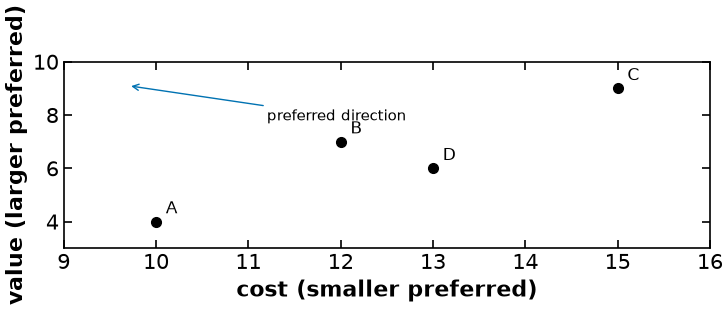

In [4]:
fig,ax=plt.subplots(figsize=(7.6,2.9))
for name,(cost,value) in results["alternatives"].items():
    ax.plot(cost,value,color="black",marker="o",linestyle="none",ms=7)
    ax.annotate(name,(cost,value),xytext=(7,6),textcoords="offset points",fontsize=12)
ax.set(xlabel="cost (smaller preferred)",ylabel="value (larger preferred)",xlim=(9,16),ylim=(3,10))
ax.annotate("preferred direction",xy=(9.7,9.1),xytext=(11.2,7.8),
            arrowprops={"arrowstyle":"->","color":"#0072B2"},fontsize=11)
fig.tight_layout()
helper.save_figure(fig,"ctx-tradespace-actual",quiet=True)
plt.show()

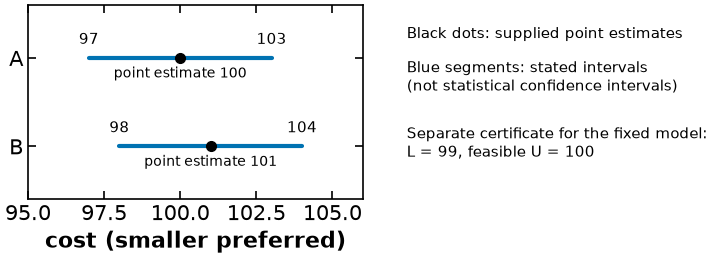

In [5]:
fig,(ax,txt)=plt.subplots(1,2,figsize=(7.6,2.9),gridspec_kw={"width_ratios":[1.35,1]})
for i,(name,row) in enumerate(results["costs"].items()):
    y=1-i
    ax.plot([row["lower"],row["upper"]],[y,y],color="#0072B2",linestyle="-",linewidth=3)
    ax.plot(row["nominal"],y,color="black",marker="o",linestyle="none",ms=7)
    for value in [row["lower"],row["upper"]]:
        ax.text(value,y+.16,f"{value:g}",ha="center",fontsize=11)
    ax.text(row["nominal"],y-.22,f'point estimate {row["nominal"]:g}',ha="center",fontsize=10)
ax.set(yticks=[1,0],yticklabels=["A","B"],xlabel="cost (smaller preferred)",xlim=(95,106),ylim=(-.6,1.6))
txt.axis("off")
txt.text(.02,.83,"Black dots: supplied point estimates",fontsize=11)
txt.text(.02,.56,"Blue segments: stated intervals\n(not statistical confidence intervals)",fontsize=11)
txt.text(.02,.22,"Separate certificate for the fixed model:\nL = 99, feasible U = 100",fontsize=11)
fig.tight_layout(w_pad=2)
helper.save_figure(fig,"ctx-ranking-actual",quiet=True)
plt.show()